# IMDb Movie Review Sentiment Analysis

## Project Overview
This project builds a machine learning model to classify movie reviews as positive or negative using Natural Language Processing (NLP).

## Dataset
IMDb Large Movie Review Dataset containing 50,000 labeled movie reviews.

## Objective
Predict whether a movie review expresses positive or negative sentiment.

In [3]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw/aclImdb")

def load_reviews(split):
    records = []

    for label in ["pos", "neg"]:
        folder = DATA_DIR / split / label
        files = list(folder.glob("*.txt"))

        for file_path in files:
            with open(file_path, "r", encoding="utf-8", errors="replace") as f:
                records.append((f.read(), label))

    return pd.DataFrame(records, columns=["review", "sentiment"])

print("Loading training data...")
train_df = load_reviews("train")

print("Loading testing data...")
test_df = load_reviews("test")

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

train_df.head()

Loading training data...
Loading testing data...
Training Shape: (25000, 2)
Testing Shape: (25000, 2)


,review,sentiment
0,Bromwell High is a cartoon comedy. It ran at t...,pos
1,Homelessness (or Houselessness as George Carli...,pos
2,Brilliant over-acting by Lesley Ann Warren. Be...,pos
3,This is easily the most underrated film inn th...,pos
4,This is not the typical Mel Brooks film. It wa...,pos


In [1]:
import sys
print(sys.executable)

c:\Users\Person-AL-Computer\Desktop\Six Projects\sentiment-analysis\.venv\Scripts\python.exe


In [4]:
print("Training Information:")
print(train_df.info())

print("\nMissing Values:")
print(train_df.isnull().sum())

print("\nDuplicate Reviews:")
print(train_df.duplicated(subset=["review"]).sum())

print("\nSentiment Distribution:")
print(train_df["sentiment"].value_counts())


Training Information:
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     25000 non-null  str  
 1   sentiment  25000 non-null  str  
dtypes: str(2)
memory usage: 32.1 MB
None

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Reviews:
96

Sentiment Distribution:
sentiment
pos    12500
neg    12500
Name: count, dtype: int64


In [5]:
duplicate_reviews = train_df[
    train_df.duplicated(subset=["review"], keep=False)
]

print("Total duplicate records:", len(duplicate_reviews))

print("\nDuplicate sentiment combinations:")
print(
    duplicate_reviews.groupby("review")["sentiment"]
    .nunique()
    .value_counts()
)


Total duplicate records: 188

Duplicate sentiment combinations:
sentiment
1    92
Name: count, dtype: int64


In [6]:
train_df_clean = train_df.drop_duplicates(
    subset=["review"],
    keep="first"
).reset_index(drop=True)

print("Original Training Shape:", train_df.shape)
print("Cleaned Training Shape:", train_df_clean.shape)

print(
    "Remaining Duplicates:",
    train_df_clean.duplicated(subset=["review"]).sum()
)

Original Training Shape: (25000, 2)
Cleaned Training Shape: (24904, 2)
Remaining Duplicates: 0


In [7]:
print("Cleaned Sentiment Distribution:")

print(train_df_clean["sentiment"].value_counts())

print("\nSentiment Percentages:")

print(
    train_df_clean["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Cleaned Sentiment Distribution:
sentiment
pos    12472
neg    12432
Name: count, dtype: int64

Sentiment Percentages:
sentiment
pos    50.08
neg    49.92
Name: proportion, dtype: float64


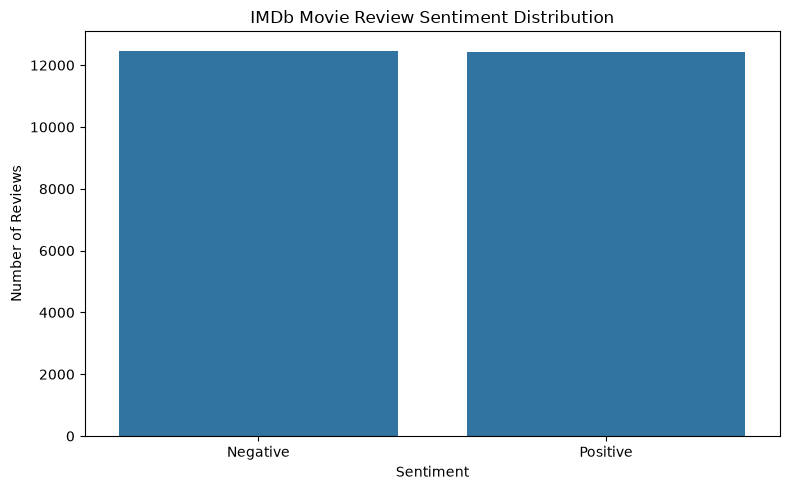

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df_clean,
    x="sentiment"
)

plt.title("IMDb Movie Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1], ["Negative", "Positive"])

plt.tight_layout()
plt.savefig("../images/sentiment_distribution.png", dpi=300)
plt.show()

In [9]:
train_df_clean["review_length"] = train_df_clean["review"].apply(len)

print("Average Review Length:")
print(
    train_df_clean.groupby("sentiment")["review_length"]
    .mean()
    .round(2)
)

Average Review Length:
sentiment
neg    1304.16
pos    1348.52
Name: review_length, dtype: float64


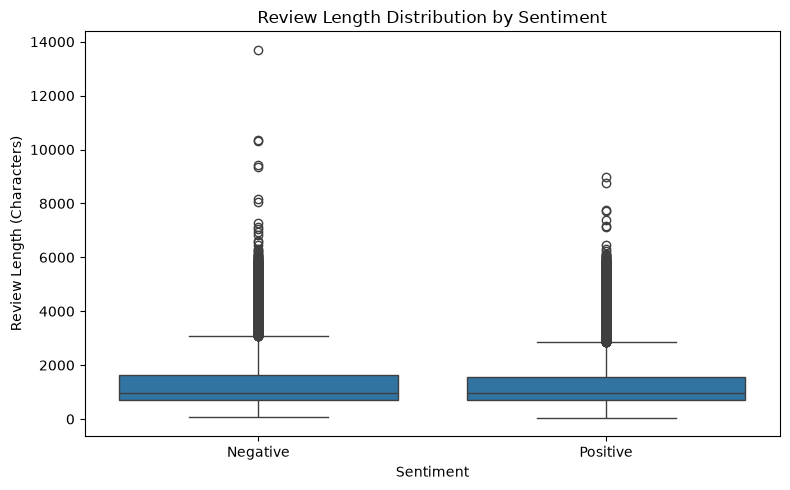

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df_clean,
    x="sentiment",
    y="review_length"
)

plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Review Length (Characters)")
plt.xticks([0, 1], ["Negative", "Positive"])

plt.tight_layout()
plt.savefig("../images/review_length_distribution.png", dpi=300)
plt.show()

In [11]:
import re
import html

def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df_clean["clean_review"] = (
    train_df_clean["review"].apply(clean_text)
)

print("Original Review:")
print(train_df_clean["review"].iloc[0][:500])

print("\nCleaned Review:")
print(train_df_clean["clean_review"].iloc[0][:500])

Original Review:
Bromwell High is a cartoon comedy. It ran at the same time as some other programs about school life, such as "Teachers". My 35 years in the teaching profession lead me to believe that Bromwell High's satire is much closer to reality than is "Teachers". The scramble to survive financially, the insightful students who can see right through their pathetic teachers' pomp, the pettiness of the whole situation, all remind me of the schools I knew and their students. When I saw the episode in which a s

Cleaned Review:
bromwell high is a cartoon comedy. it ran at the same time as some other programs about school life, such as "teachers". my 35 years in the teaching profession lead me to believe that bromwell high's satire is much closer to reality than is "teachers". the scramble to survive financially, the insightful students who can see right through their pathetic teachers' pomp, the pettiness of the whole situation, all remind me of the schools i knew and their students. 

In [12]:
print("Empty Cleaned Reviews:")
print((train_df_clean["clean_review"].str.len() == 0).sum())

print("\nMissing Cleaned Reviews:")
print(train_df_clean["clean_review"].isnull().sum())

print("\nOriginal vs Cleaned Review Length:")
print(
    train_df_clean[
        ["review_length", "clean_review"]
    ].head(5)
)

Empty Cleaned Reviews:
0

Missing Cleaned Reviews:
0

Original vs Cleaned Review Length:
   review_length                                       clean_review
0            806  bromwell high is a cartoon comedy. it ran at t...
1           2366  homelessness (or houselessness as george carli...
2            841  brilliant over-acting by lesley ann warren. be...
3            663  this is easily the most underrated film inn th...
4            647  this is not the typical mel brooks film. it wa...


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(
    train_df_clean["clean_review"]
)

y_train = train_df_clean["sentiment"].map({
    "neg": 0,
    "pos": 1
})

print("TF-IDF Training Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)
print("Vocabulary Size:", len(tfidf.vocabulary_))

TF-IDF Training Shape: (24904, 50000)
Training Labels Shape: (24904,)
Vocabulary Size: 50000


In [14]:
feature_names = tfidf.get_feature_names_out()

print("First 30 TF-IDF Features:")

print(feature_names[:30])

First 30 TF-IDF Features:
['00' '000' '000 000' '000 to' '007' '01' '10' '10 000' '10 10' '10 and'
 '10 as' '10 because' '10 bethany' '10 but' '10 for' '10 from' '10 if'
 '10 in' '10 is' '10 it' '10 items' '10 lines' '10 minutes' '10 of'
 '10 on' '10 or' '10 out' '10 rating' '10 seconds' '10 stars']


In [15]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [16]:
test_df_clean = test_df.copy()

test_df_clean["clean_review"] = (
    test_df_clean["review"].apply(clean_text)
)

X_test = tfidf.transform(
    test_df_clean["clean_review"]
)

y_test = test_df_clean["sentiment"].map({
    "neg": 0,
    "pos": 1
})

print("Testing Features Shape:", X_test.shape)
print("Testing Labels Shape:", y_test.shape)
print("Testing Data Prepared Successfully!")

Testing Features Shape: (25000, 50000)
Testing Labels Shape: (25000,)
Testing Data Prepared Successfully!


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = lr_model.predict(X_test)

print("Logistic Regression Performance")
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-Score:", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

Logistic Regression Performance
--------------------------------
Accuracy: 0.8993
Precision: 0.8959
Recall: 0.9036
F1-Score: 0.8997

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.90      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



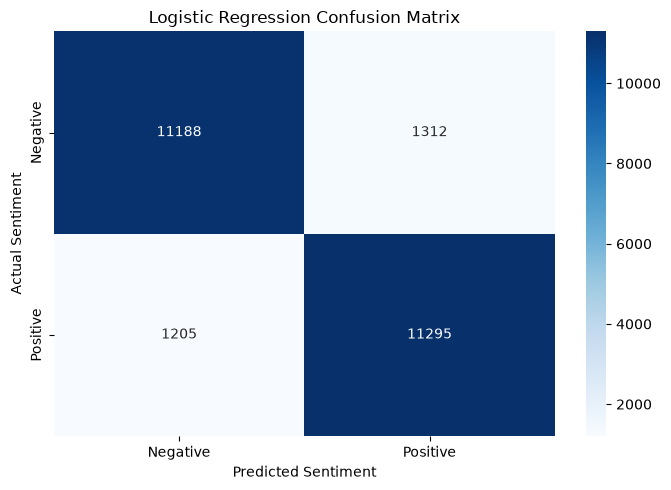

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()
plt.savefig("../images/logistic_regression_confusion_matrix.png", dpi=300)
plt.show()

In [19]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

print("Multinomial Naive Bayes Model Trained Successfully!")

Multinomial Naive Bayes Model Trained Successfully!


In [20]:
nb_pred = nb_model.predict(X_test)

print("Multinomial Naive Bayes Performance")
print("-----------------------------------")

print("Accuracy:", round(accuracy_score(y_test, nb_pred), 4))
print("Precision:", round(precision_score(y_test, nb_pred), 4))
print("Recall:", round(recall_score(y_test, nb_pred), 4))
print("F1-Score:", round(f1_score(y_test, nb_pred), 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    nb_pred,
    target_names=["Negative", "Positive"]
))

Multinomial Naive Bayes Performance
-----------------------------------
Accuracy: 0.872
Precision: 0.8867
Recall: 0.853
F1-Score: 0.8696

Classification Report:
              precision    recall  f1-score   support

    Negative       0.86      0.89      0.87     12500
    Positive       0.89      0.85      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000



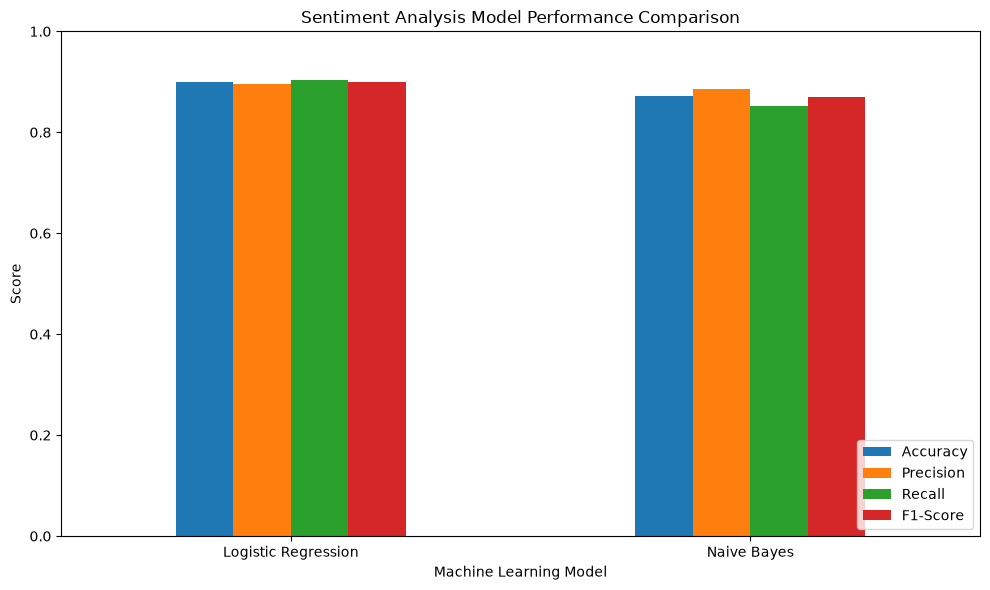

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8993,0.8959,0.9036,0.8997
1,Naive Bayes,0.8720,0.8867,0.8530,0.8696


In [21]:
models = ["Logistic Regression", "Naive Bayes"]

accuracy = [0.8993, 0.8720]
precision = [0.8959, 0.8867]
recall = [0.9036, 0.8530]
f1 = [0.8997, 0.8696]

comparison_df = pd.DataFrame({
    "Model": models,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})

comparison_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Analysis Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "../images/model_performance_comparison.png",
    dpi=300
)

plt.show()

comparison_df

In [22]:
comparison_df.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison table saved successfully!")

Model comparison table saved successfully!


In [23]:
from sklearn.metrics import roc_auc_score

lr_probabilities = lr_model.predict_proba(X_test)[:, 1]
nb_probabilities = nb_model.predict_proba(X_test)[:, 1]

lr_auc = roc_auc_score(y_test, lr_probabilities)
nb_auc = roc_auc_score(y_test, nb_probabilities)

print("Logistic Regression ROC-AUC:", round(lr_auc, 4))
print("Naive Bayes ROC-AUC:", round(nb_auc, 4))

Logistic Regression ROC-AUC: 0.963
Naive Bayes ROC-AUC: 0.9449


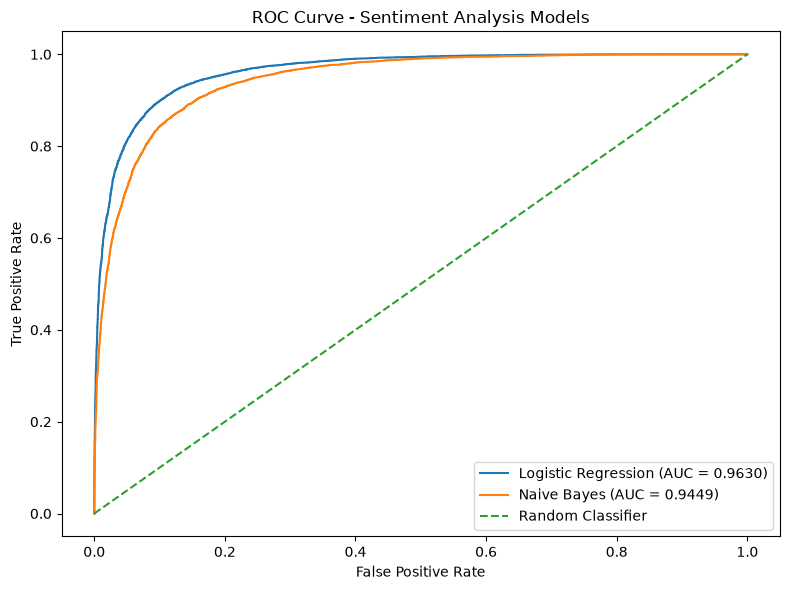

In [24]:
from sklearn.metrics import roc_curve

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probabilities)
nb_fpr, nb_tpr, _ = roc_curve(y_test, nb_probabilities)

plt.figure(figsize=(8, 6))

plt.plot(
    lr_fpr, lr_tpr,
    label=f"Logistic Regression (AUC = {lr_auc:.4f})"
)

plt.plot(
    nb_fpr, nb_tpr,
    label=f"Naive Bayes (AUC = {nb_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve - Sentiment Analysis Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig("../images/roc_curve_comparison.png", dpi=300)
plt.show()

In [25]:
roc_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes"],
    "ROC_AUC": [lr_auc, nb_auc]
})

roc_results.to_csv(
    "../reports/roc_auc_results.csv",
    index=False
)

print("ROC-AUC results saved successfully!")

ROC-AUC results saved successfully!


In [26]:
import joblib

joblib.dump(
    lr_model,
    "../models/logistic_regression_model.pkl"
)

joblib.dump(
    tfidf,
    "../models/tfidf_vectorizer.pkl"
)

joblib.dump(
    nb_model,
    "../models/naive_bayes_model.pkl"
)

print("All trained models and TF-IDF vectorizer saved successfully!")

All trained models and TF-IDF vectorizer saved successfully!


In [27]:
sample_reviews = [
    "This movie was absolutely amazing. I loved every moment!",
    "This movie was terrible and boring. A complete waste of time.",
    "The acting was good but the story was average."
]

cleaned_reviews = [
    clean_text(review) for review in sample_reviews
]

sample_features = tfidf.transform(cleaned_reviews)

predictions = lr_model.predict(sample_features)
probabilities = lr_model.predict_proba(sample_features)

for review, prediction, probability in zip(
    sample_reviews, predictions, probabilities
):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Confidence:", round(max(probability) * 100, 2), "%")
    print("-" * 60)

Review: This movie was absolutely amazing. I loved every moment!
Predicted Sentiment: Positive
Confidence: 85.27 %
------------------------------------------------------------
Review: This movie was terrible and boring. A complete waste of time.
Predicted Sentiment: Negative
Confidence: 99.69 %
------------------------------------------------------------
Review: The acting was good but the story was average.
Predicted Sentiment: Negative
Confidence: 69.88 %
------------------------------------------------------------


In [28]:
def predict_sentiment(review):
    cleaned = clean_text(review)
    features = tfidf.transform([cleaned])

    prediction = lr_model.predict(features)[0]
    probabilities = lr_model.predict_proba(features)[0]

    sentiment = "Positive" if prediction == 1 else "Negative"
    confidence = max(probabilities) * 100

    return sentiment, round(confidence, 2)


result, confidence = predict_sentiment(
    "The movie was fantastic and very entertaining!"
)

print("Sentiment:", result)
print("Confidence:", confidence, "%")

Sentiment: Positive
Confidence: 91.64 %
